# 04 · Regression: predicting age at diagnosis

**Task.** Predict `Age_at_diagnosis` (years) from gender, race and the 20 mutations. **The grade is not a predictor** (decision taken before the project started): the question is how much of a patient's age can be explained by the clinical and mutation profile alone.

**Protocol** (same for every model, see `docs/DECISIONS.md`):
- **Nested cross-validation** on all 839 patients (scheme of the course notebook `Example_ExtrOSA_ModelTuning_NestedLoop`): 10 outer folds estimate performance; inside each outer training part, `GridSearchCV` with 3 inner folds chooses the hyperparameters. Folds are shuffled with seed 42.
- Preprocessing (scaling, one-hot encoding of race) is inside each model's `Pipeline`, so it is re-fitted on every training part.
- **Inner selection criterion: RMSE** (the squared-error loss most of these models minimise). **Reported metrics:** MAE (years, easy to interpret), RMSE (years, penalises large errors more) and R² (share of the variance of age explained), always compared with the **mean baseline** (predicting the mean age of the training part, R² ≈ 0).
- Every patient gets exactly one **out-of-fold prediction** from a model that never saw them. Metrics are computed on these predictions, with **95% bootstrap intervals** (2000 resamples of patients, the same resamples for every model).
- **Comparison rule:** a model is not declared better than another if their 95% intervals overlap. A paired bootstrap of the difference is reported as a complementary, more sensitive check.
- **Final models** for interpretation: the same tuning procedure applied once to all patients (`GridSearchCV` with 3 folds on the full data, then refit with the chosen values). Their in-sample fit is **not** a performance estimate.

| # | Section |
|---|---|
| 1 | Setup |
| 2 | Models and hyperparameter grids |
| 3 | Nested cross-validation |
| 4 | Model comparison |
| 5 | Chosen hyperparameters across folds |
| 6 | Out-of-fold predictions and residuals |
| 7 | Multiple linear regression: coefficients, VIF, residual diagnostics |
| 8 | Ridge and Lasso: shrinkage and variable selection |
| 9 | Decision tree |
| 10 | Permutation importance |
| 11 | Summary |

In [1]:
import sys, time
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "config.py").exists():
    if ROOT.parent == ROOT:
        raise RuntimeError("Project root (folder containing src/config.py) not found")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy import stats
from IPython.display import display

from src import config, data, eda, evaluation as ev, models, plotting, reporting
from src.pipelines import format_value, readable_names
from src.plotting import CLASS_COLORS, NEUTRAL

plotting.set_style()
pd.set_option("display.precision", 3)

df = data.load_processed()
FEATURES = data.feature_columns("regression")
X = df[FEATURES]
y = df[config.REGRESSION_TARGET].values
grade = df["Grade"].map(config.CLASS_LABELS).values    # only to describe the results, never an input
results = {"features": FEATURES, "n": len(y)}
print(f"{len(y)} patients, {len(FEATURES)} predictors: {FEATURES}")

839 patients, 22 predictors: ['Gender', 'Race', 'IDH1', 'TP53', 'ATRX', 'PTEN', 'EGFR', 'CIC', 'MUC16', 'PIK3CA', 'NF1', 'PIK3R1', 'FUBP1', 'RB1', 'NOTCH1', 'BCOR', 'CSMD3', 'SMARCA4', 'GRIN2A', 'IDH2', 'FAT4', 'PDGFRA']


## 2. Models and hyperparameter grids

From the simplest to the most flexible. Linear models and SVR receive standardised inputs; trees do not need scaling. Each grid covers the hyperparameters discussed in the course for that model.

In [2]:
MODELS = models.regression_models(FEATURES)
grid_rows = []
for name, (pipe, grid) in MODELS.items():
    grid_rows.append({"Model": name,
                      "Hyperparameters searched": "; ".join(f"{k.split('__')[1]} in [{', '.join(format_value(x) for x in v)}]"
                                                            for k, v in grid.items()) or "none",
                      "Configurations": int(np.prod([len(v) for v in grid.values()])) if grid else 1})
grids = pd.DataFrame(grid_rows)
with pd.option_context("display.max_colwidth", None):
    display(grids)
for name, note in models.REGRESSION_GRID_NOTES.items():
    print(f"{name}: {note}")
reporting.save_table_tex(grids, "reg_models_grids", column_format="lp{10.5cm}r")

,Model,Hyperparameters searched,Configurations
0,Mean baseline,none,1
1,Linear regression,none,1
2,Ridge,"alpha in [0.01, 0.03162, 0.1, 0.3162, 1, 3.162, 10, 31.62, 100, 316.2, 1000]",11
3,Lasso,"alpha in [0.001, 0.003162, 0.01, 0.03162, 0.1, 0.3162, 1, 3.162, 10]",9
4,Decision tree,"max_depth in [2, 3, 4, 5, 6, 8]; min_samples_leaf in [5, 10, 20, 40]",24
5,Random forest,"max_features in [0.33, 0.66, 1]; min_samples_leaf in [1, 5, 10, 20]",12
6,XGBoost,"n_estimators in [100, 300]; learning_rate in [0.03, 0.1]; max_depth in [2, 3, 5]",12
7,SVR,"C in [1, 10, 100]; epsilon in [0.5, 2, 5]; gamma in [scale, 0.01, 0.1]",27


Ridge: alpha: strength of the L2 penalty (larger = coefficients shrunk towards 0)
Lasso: alpha: strength of the L1 penalty (larger = more coefficients set exactly to 0)
Decision tree: max_depth and min_samples_leaf limit the size of the tree (pre-pruning against overfitting)
Random forest: max_features: share of features tried at each split (decorrelates the trees); min_samples_leaf: smallest leaf; 300 trees fixed (more trees do not overfit, only cost time)
XGBoost: n_estimators x learning_rate (shrinkage) control how far boosting goes; max_depth: size of each tree
SVR: C: penalty of errors outside the tube; epsilon: half-width of the tube (years) in which errors are not penalised; gamma: reach of each support vector in the RBF kernel


WindowsPath('C:/Users/ori/ML/results/tables/reg_models_grids.tex')

## 3. Nested cross-validation

This is the slow step (a few minutes): for every model, 10 outer folds × (number of configurations × 3 inner folds) fits. Permutation importance is also computed on each outer test fold (Section 10).

In [3]:
NESTED = {}
t0 = time.time()
for name, (pipe, grid) in MODELS.items():
    t = time.time()
    NESTED[name] = ev.nested_cv(pipe, grid, X, y, task="regression", scoring=ev.REGRESSION_SCORING,
                                metric_fn=ev.regression_metrics, importance=(name != "Mean baseline"))
    m = ev.regression_metrics(y, NESTED[name]["oof"])
    print(f"{name:<18} MAE = {m['MAE']:.2f}  RMSE = {m['RMSE']:.2f}  R2 = {m['R2']:.3f}   ({time.time() - t:.0f} s)")
print(f"Total: {time.time() - t0:.0f} s")

oof = pd.DataFrame({"Case_ID": df[config.ID_COL], "Age_at_diagnosis": y,
                    **{name: r["oof"] for name, r in NESTED.items()}})
oof.to_csv(config.LOGS / "04_regression_oof_predictions.csv", index=False)

Mean baseline      MAE = 13.23  RMSE = 15.71  R2 = -0.002   (0 s)


Linear regression  MAE = 9.82  RMSE = 12.41  R2 = 0.374   (8 s)


Ridge              MAE = 9.84  RMSE = 12.38  R2 = 0.377   (10 s)


Lasso              MAE = 9.83  RMSE = 12.35  R2 = 0.381   (7 s)


Decision tree      MAE = 9.79  RMSE = 12.33  R2 = 0.382   (6 s)


Random forest      MAE = 9.68  RMSE = 12.18  R2 = 0.397   (63 s)


XGBoost            MAE = 9.75  RMSE = 12.22  R2 = 0.394   (10 s)


SVR                MAE = 9.80  RMSE = 12.47  R2 = 0.369   (19 s)
Total: 122 s


## 4. Model comparison

Two views of the same out-of-fold predictions:
- **Pooled** metrics over all 839 patients with bootstrap 95% intervals (used for the comparison rule).
- **Per-fold** mean ± SD over the 10 outer folds (shows how much the estimate moves between test sets).

In [4]:
rows = []
for name, r in NESTED.items():
    cis = ev.metric_cis(y, r["oof"], ev.regression_metrics)
    row = {"Model": name}
    for metric, (point, lo, hi) in cis.items():
        row.update({metric: point, f"{metric} CI low": lo, f"{metric} CI high": hi})
    for metric in ("MAE", "RMSE", "R2"):
        row[f"{metric} fold mean"] = r["folds"][metric].mean()
        row[f"{metric} fold SD"] = r["folds"][metric].std()
    rows.append(row)
summary = pd.DataFrame(rows)
display(summary[["Model", "MAE", "MAE CI low", "MAE CI high", "RMSE", "RMSE CI low", "RMSE CI high",
                 "R2", "R2 CI low", "R2 CI high"]])
results["summary"] = summary.to_dict(orient="records")

best_mae, ties_mae = ev.best_and_ties(summary, "MAE", lower_is_better=True)
best_r2, ties_r2 = ev.best_and_ties(summary, "R2", lower_is_better=False)
print(f"Lowest MAE: {best_mae}; models whose MAE interval overlaps it: {ties_mae}")
print(f"Highest R2: {best_r2}; models whose R2 interval overlaps it: {ties_r2}")
results["best_mae"], results["ties_mae"] = best_mae, ties_mae
results["best_r2"], results["ties_r2"] = best_r2, ties_r2

tex = pd.DataFrame({
    "Model": summary["Model"],
    "MAE (years)": [f"{a:.2f} [{b:.2f}, {c:.2f}]" for a, b, c in summary[["MAE", "MAE CI low", "MAE CI high"]].values],
    "RMSE (years)": [f"{a:.2f} [{b:.2f}, {c:.2f}]" for a, b, c in summary[["RMSE", "RMSE CI low", "RMSE CI high"]].values],
    "R2": [f"{a:.3f} [{b:.3f}, {c:.3f}]" for a, b, c in summary[["R2", "R2 CI low", "R2 CI high"]].values],
    "R2 per fold": [f"{a:.3f} ± {b:.3f}" for a, b in summary[["R2 fold mean", "R2 fold SD"]].values],
})
reporting.save_table_tex(tex, "reg_model_comparison", column_format="lllll")

,Model,MAE,MAE CI low,MAE CI high,RMSE,RMSE CI low,RMSE CI high,R2,R2 CI low,R2 CI high
0,Mean baseline,13.226,12.643,13.801,15.710,15.129,16.264,-0.002,-0.008,-0.001
1,Linear regression,9.824,9.289,10.349,12.412,11.785,13.043,0.374,0.313,0.428
2,Ridge,9.835,9.305,10.349,12.385,11.764,12.995,0.377,0.319,0.429
3,Lasso,9.834,9.305,10.339,12.346,11.733,12.944,0.381,0.328,0.427
4,Decision tree,9.789,9.245,10.320,12.333,11.695,12.970,0.382,0.322,0.436
5,Random forest,9.678,9.154,10.183,12.183,11.581,12.775,0.397,0.344,0.446
6,XGBoost,9.750,9.230,10.258,12.218,11.616,12.802,0.394,0.344,0.440
7,SVR,9.805,9.288,10.327,12.468,11.845,13.087,0.369,0.311,0.420


Lowest MAE: Random forest; models whose MAE interval overlaps it: ['Linear regression', 'Ridge', 'Lasso', 'Decision tree', 'XGBoost', 'SVR']
Highest R2: Random forest; models whose R2 interval overlaps it: ['Linear regression', 'Ridge', 'Lasso', 'Decision tree', 'XGBoost', 'SVR']


WindowsPath('C:/Users/ori/ML/results/tables/reg_model_comparison.tex')

,Model,MAE - baseline,CI low (baseline),CI high (baseline),MAE - Random forest,CI low (best),CI high (best)
0,Linear regression,-3.401,-3.973,-2.817,0.146,-0.027,0.319
1,Ridge,-3.390,-3.941,-2.825,0.157,-0.016,0.324
2,Lasso,-3.392,-3.887,-2.876,0.155,-0.016,0.320
3,Decision tree,-3.436,-4.001,-2.855,0.111,-0.043,0.265
4,Random forest,-3.547,-4.091,-3.001,0.000,0.000,0.000
5,XGBoost,-3.475,-3.991,-2.950,0.072,-0.057,0.196
6,SVR,-3.421,-4.000,-2.852,0.126,-0.055,0.310


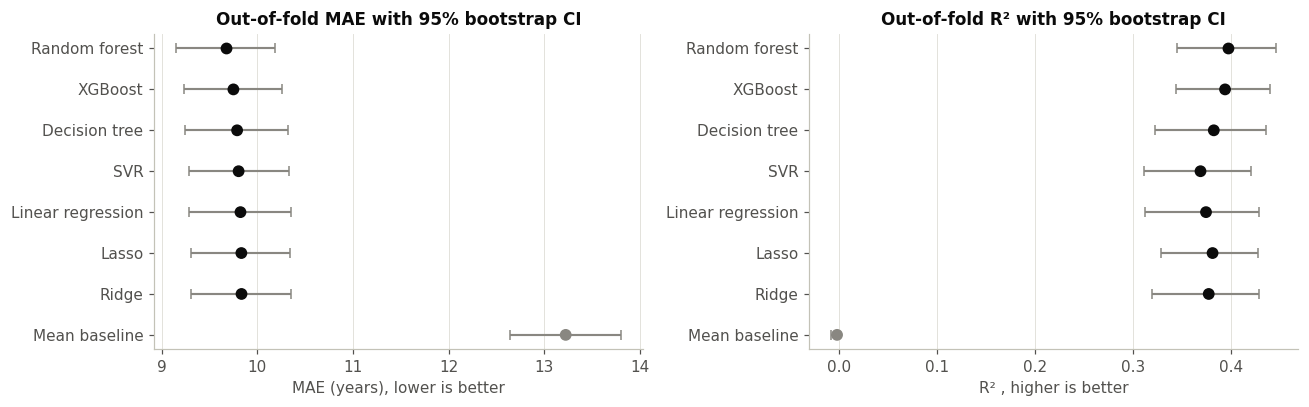

In [5]:
# Paired bootstrap: each model against the mean baseline and against the model with the lowest MAE
mae = lambda t, p: np.mean(np.abs(t - p))
paired = []
for name, r in NESTED.items():
    if name == "Mean baseline":
        continue
    d_base = ev.paired_difference_ci(y, r["oof"], NESTED["Mean baseline"]["oof"], mae)
    d_best = ev.paired_difference_ci(y, r["oof"], NESTED[best_mae]["oof"], mae) if name != best_mae else (0.0, 0.0, 0.0)
    paired.append({"Model": name,
                   "MAE - baseline": d_base[0], "CI low (baseline)": d_base[1], "CI high (baseline)": d_base[2],
                   f"MAE - {best_mae}": d_best[0], "CI low (best)": d_best[1], "CI high (best)": d_best[2]})
paired = pd.DataFrame(paired)
display(paired)
results["paired_mae_differences"] = paired.to_dict(orient="records")
paired_tex = pd.DataFrame({
    "Model": paired["Model"],
    "MAE difference vs mean baseline": [f"{a:+.2f} [{b:+.2f}, {c:+.2f}]" for a, b, c in paired.iloc[:, 1:4].values],
    f"MAE difference vs {best_mae}": [f"{a:+.2f} [{b:+.2f}, {c:+.2f}]" for a, b, c in paired.iloc[:, 4:7].values],
})
reporting.save_table_tex(paired_tex, "reg_paired_differences", column_format="lll")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
order = summary.sort_values("MAE", ascending=False)["Model"].tolist()
s = summary.set_index("Model").loc[order]
for ax, metric, label in ((axes[0], "MAE", "MAE (years), lower is better"), (axes[1], "R2", "R² , higher is better")):
    err = np.clip([s[metric] - s[f"{metric} CI low"], s[f"{metric} CI high"] - s[metric]], 0, None)
    colors = [NEUTRAL if m == "Mean baseline" else plotting.INK for m in order]
    ax.errorbar(s[metric], np.arange(len(order)), xerr=err, fmt="none", ecolor=NEUTRAL, elinewidth=1.4, capsize=3)
    ax.scatter(s[metric], np.arange(len(order)), color=colors, s=45, zorder=3)
    ax.set_yticks(np.arange(len(order)), order)
    ax.set_xlabel(label); ax.grid(axis="y", visible=False)
axes[0].set_title("Out-of-fold MAE with 95% bootstrap CI")
axes[1].set_title("Out-of-fold R² with 95% bootstrap CI")
fig.tight_layout()
plotting.save_figure(fig, "reg_model_comparison")
plt.show()

## 5. Chosen hyperparameters across the outer folds

Each outer fold runs its own grid search, so the chosen values can differ between folds. If the same values are chosen in most folds, the choice is stable; if they jump around, several configurations perform similarly (the performance surface is flat), and the exact value matters little.

The **final models** apply the same search once to all patients; their hyperparameters are listed in the last column.

In [6]:
FINAL = {}
hp_rows = []
for name, (pipe, grid) in MODELS.items():
    if not grid:
        FINAL[name] = ev.fit_final(pipe, grid, X, y, "regression", ev.REGRESSION_SCORING)
        continue
    FINAL[name] = ev.fit_final(pipe, grid, X, y, "regression", ev.REGRESSION_SCORING)
    folds = NESTED[name]["folds"]
    for p in [k.split("__")[1] for k in grid]:
        counts = folds[p].map(format_value).value_counts()
        hp_rows.append({"Model": name, "Hyperparameter": p,
                        "Values chosen in the 10 outer folds": ", ".join(f"{v} ({n})" for v, n in counts.items()),
                        "Final model (all data)": format_value(FINAL[name][1][p])})
hp = pd.DataFrame(hp_rows)
with pd.option_context("display.max_colwidth", None):
    display(hp)
reporting.save_table_tex(hp, "reg_hyperparameters", column_format="llp{7cm}l")
results["hyperparameters"] = hp.to_dict(orient="records")
results["final_hyperparameters"] = {name: params for name, (model, params) in FINAL.items()}

,Model,Hyperparameter,Values chosen in the 10 outer folds,Final model (all data)
0,Ridge,alpha,"31.62 (9), 100 (1)",31.62
1,Lasso,alpha,"1 (6), 0.3162 (4)",0.3162
2,Decision tree,max_depth,"3 (5), 2 (2), 4 (2), 8 (1)",3
3,Decision tree,min_samples_leaf,"5 (5), 10 (5)",5
4,Random forest,max_features,"0.33 (8), 0.66 (2)",0.33
5,Random forest,min_samples_leaf,5 (10),5
6,XGBoost,n_estimators,100 (10),100
7,XGBoost,learning_rate,0.03 (10),0.03
8,XGBoost,max_depth,"2 (8), 3 (2)",2
9,SVR,C,10 (10),10


## 6. Out-of-fold predictions and residuals

Observed vs predicted age for the model with the lowest MAE, on the out-of-fold predictions. Points on the diagonal are perfect predictions. Points are coloured by grade **only to interpret** the result (the grade was not an input). If the predictions form two groups, the question is *which* variable defines them: the grade, or the IDH status that is strongly associated with it. Both correlations are computed, and the mean predicted age is shown in the four groups defined by grade and IDH status (IDH1 or IDH2 mutated): if the model followed the grade, IDH-mutant and wildtype patients of the same grade would get similar predictions.

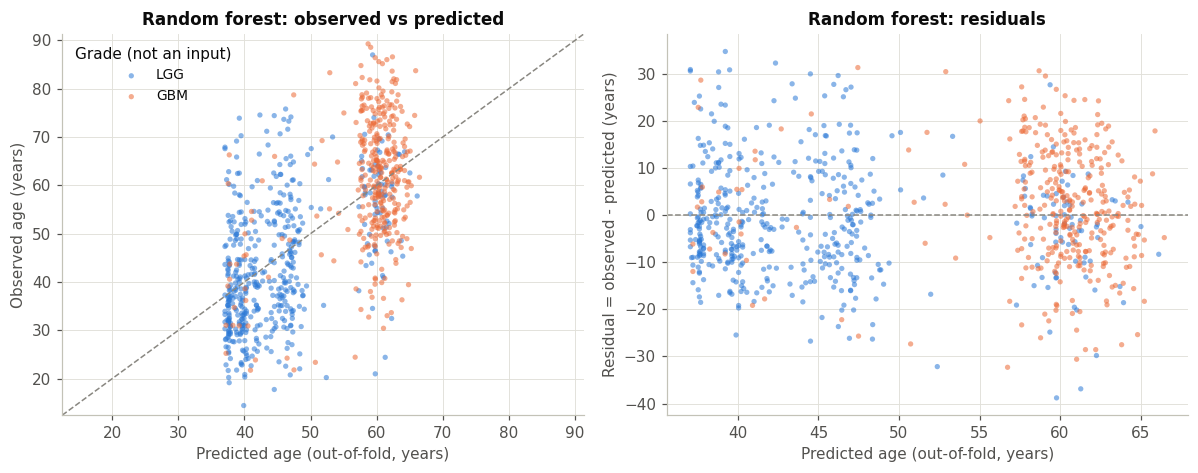

,Observed,Predicted,Absolute error
Grade,,,
LGG,43.875,45.039,9.414
GBM,60.704,58.944,10.044


Correlation between predicted age and grade (point-biserial): 0.705
Correlation between predicted age and IDH status (IDH1 or IDH2 mutated): -0.931


n  Observed  Predicted
Grade IDH                                   
LGG   IDH wildtype   85    54.659     59.016
      IDH mutant    402    41.595     42.083
GBM   IDH wildtype  327    62.224     60.374
      IDH mutant     25    40.822     40.236

WindowsPath('C:/Users/ori/ML/results/tables/reg_pred_by_grade_idh.tex')

In [7]:
best_pred = NESTED[best_mae]["oof"]
resid = y - best_pred
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
ax = axes[0]
for label in ("LGG", "GBM"):
    m = grade == label
    ax.scatter(best_pred[m], y[m], s=12, alpha=0.55, color=CLASS_COLORS[label], label=label, edgecolor="none")
lims = [min(y.min(), best_pred.min()) - 2, max(y.max(), best_pred.max()) + 2]
ax.plot(lims, lims, color=NEUTRAL, ls="--", lw=1)
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel("Predicted age (out-of-fold, years)"); ax.set_ylabel("Observed age (years)")
ax.set_title(f"{best_mae}: observed vs predicted"); ax.legend(title="Grade (not an input)")
ax = axes[1]
for label in ("LGG", "GBM"):
    m = grade == label
    ax.scatter(best_pred[m], resid[m], s=12, alpha=0.55, color=CLASS_COLORS[label], edgecolor="none")
ax.axhline(0, color=NEUTRAL, ls="--", lw=1)
ax.set_xlabel("Predicted age (out-of-fold, years)"); ax.set_ylabel("Residual = observed - predicted (years)")
ax.set_title(f"{best_mae}: residuals")
fig.tight_layout()
plotting.save_figure(fig, "reg_oof_predictions")
plt.show()

by_grade = pd.DataFrame({"Grade": grade, "Observed": y, "Predicted": best_pred, "Absolute error": np.abs(resid)}) \
    .groupby("Grade")[["Observed", "Predicted", "Absolute error"]].mean().loc[["LGG", "GBM"]]
display(by_grade)
results["oof_by_grade_best_model"] = by_grade.to_dict(orient="index")
print("Correlation between predicted age and grade (point-biserial):",
      round(stats.pointbiserialr(df["Grade"], best_pred).statistic, 3))
results["corr_prediction_grade"] = stats.pointbiserialr(df["Grade"], best_pred).statistic
idh_mut = ((df["IDH1"] == 1) | (df["IDH2"] == 1)).astype(int).values
results["corr_prediction_idh"] = stats.pointbiserialr(idh_mut, best_pred).statistic
print("Correlation between predicted age and IDH status (IDH1 or IDH2 mutated):", round(results["corr_prediction_idh"], 3))
by_idh = pd.DataFrame({"Grade": grade, "IDH": np.where(idh_mut == 1, "IDH mutant", "IDH wildtype"), "Observed": y, "Predicted": best_pred}) \
    .groupby(["Grade", "IDH"]).agg(n=("Observed", "size"), Observed=("Observed", "mean"), Predicted=("Predicted", "mean")) \
    .reindex(pd.MultiIndex.from_product([["LGG", "GBM"], ["IDH wildtype", "IDH mutant"]], names=["Grade", "IDH"]))
display(by_idh)
results["oof_by_grade_idh_best_model"] = {f"{g} | {i}": r.to_dict() for (g, i), r in by_idh.iterrows()}
reporting.save_table_tex(by_idh.reset_index(), "reg_pred_by_grade_idh", float_format="{:.1f}", column_format="llrrr")

## 7. Multiple linear regression: coefficients, VIF and residual diagnostics

For interpretation the linear model is refitted with `statsmodels` on all patients, with the binary predictors **unscaled**, so each coefficient is the difference in mean age (years) between patients with and without that mutation, holding the other predictors fixed. Race is one-hot encoded with *white* as reference (the largest group).

The p-values and confidence intervals assume independent, normal errors with constant variance; the diagnostic plots check these assumptions (course slides, Chapter 3: non-linearity, non-constant variance, outliers, high-leverage points, collinearity). Cook's distance above 1 flags an influential patient. A patient with **leverage 1** (the only one with a given value of a predictor) is fitted exactly, so its residual carries no information and its Cook's distance is undefined; such patients are reported and left out of the diagnostic plots.

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.414
Model:                            OLS   Adj. R-squared:                  0.397
Method:                 Least Squares   F-statistic:                     23.98
Date:                Sun, 25 Oct 2026   Prob (F-statistic):           2.78e-78
Time:                        17:24:26   Log-Likelihood:                -3276.1
No. Observations:                 839   AIC:                             6602.
Df Residuals:                     814   BIC:                             6720.
Df Model:                          24                                         
Covariance Type:            nonrobust                                         


,Coefficient (years),CI low,CI high,p-value,p BH
IDH1,-16.726,-19.397,-14.055,5.688e-32,1.365e-30
IDH2,-21.043,-26.475,-15.612,7.864e-14,9.436e-13
ATRX,-4.940,-7.455,-2.424,1.254e-04,1.003e-03
TP53,-2.120,-4.348,0.109,6.229e-02,3.737e-01
PIK3R1,2.910,-0.540,6.359,9.814e-02,4.711e-01
MUC16,1.884,-0.766,4.534,1.632e-01,6.527e-01
Race_native,-13.470,-37.486,10.546,2.713e-01,6.657e-01
GRIN2A,-2.669,-7.566,2.228,2.850e-01,6.657e-01
NF1,-1.708,-4.925,1.510,2.979e-01,6.657e-01
BCOR,2.435,-2.249,7.118,3.079e-01,6.657e-01


Maximum VIF: 2.61 ( IDH1 )
Patients with leverage = 1: [('TCGA-HT-A617', ['Race_native'])]
Max Cook's distance (excluding leverage 1): 0.062 | Breusch-Pagan p: 0.03 | Shapiro p (residuals): 2.84e-02


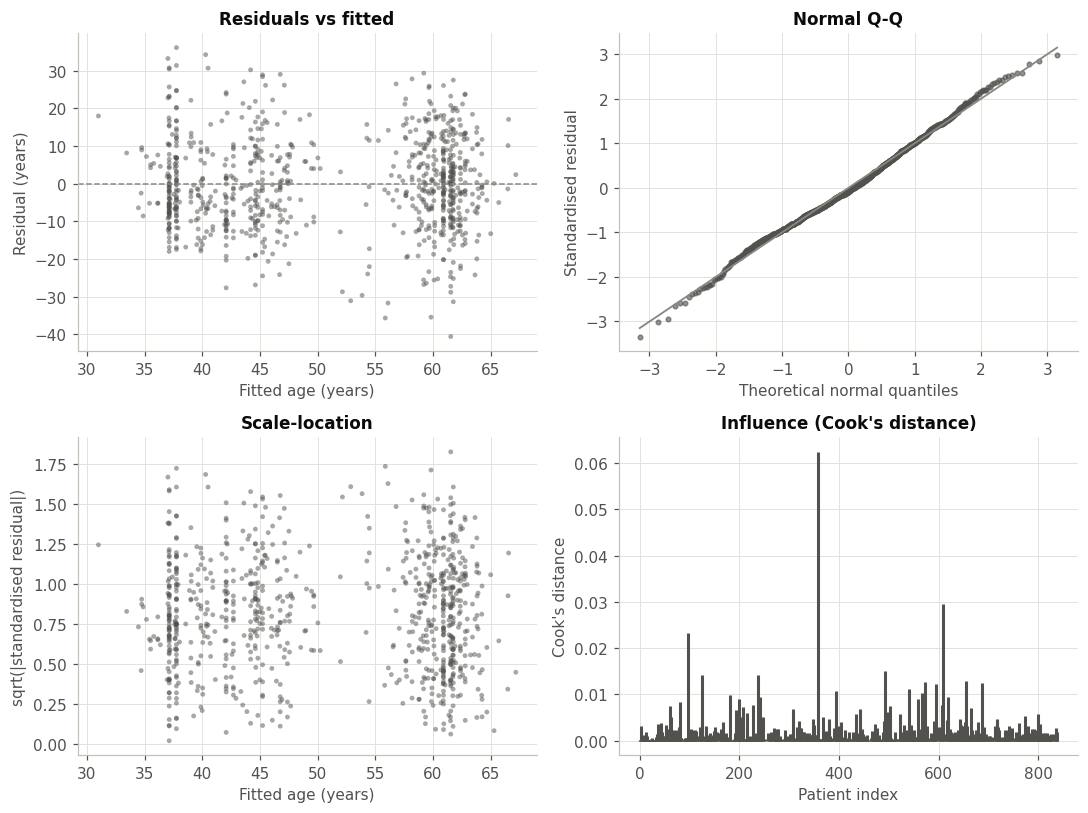

In [8]:
race = pd.get_dummies(df["Race"].map({0: "White", 1: "Race_black", 2: "Race_asian", 3: "Race_native"})) \
    .drop(columns="White").astype(int)
X_ols = pd.concat([df[["Gender"]], race, df[config.GENE_COLS]], axis=1)
ols = sm.OLS(y, sm.add_constant(X_ols.astype(float))).fit()
print(ols.summary().tables[0])
coef = pd.DataFrame({"Coefficient (years)": ols.params, "CI low": ols.conf_int()[0], "CI high": ols.conf_int()[1],
                     "p-value": ols.pvalues}).drop(index="const")
coef["p BH"] = eda.adjust_pvalues(coef["p-value"].values)[1]
coef = coef.sort_values("p-value")
display(coef)
results["ols"] = {"r2_in_sample": ols.rsquared, "adj_r2_in_sample": ols.rsquared_adj, "f_pvalue": ols.f_pvalue,
                  "intercept": ols.params["const"], "coefficients": coef.to_dict(orient="index")}
tex = coef.reset_index().rename(columns={"index": "Predictor"})
for c in ["p-value", "p BH"]:
    tex[c] = tex[c].map(lambda p: f"{p:.1e}")
reporting.save_table_tex(tex, "reg_ols_coefficients", float_format="{:.2f}", column_format="lrrrrr")

vif = eda.vif_table(X_ols)
print("Maximum VIF:", round(vif["VIF"].max(), 2), "(", vif.iloc[0]["Feature"], ")")
results["ols"]["vif"] = vif.to_dict(orient="records")

influence = ols.get_influence()
leverage = influence.hat_matrix_diag
# A patient with leverage 1 is fitted exactly (its residual is 0 by construction), so its
# standardised residual and Cook's distance are undefined (0/0). This happens when a predictor
# column is 1 for a single patient: here the only American Indian or Alaska Native patient.
full_leverage = np.flatnonzero(leverage > 1 - 1e-8)
print("Patients with leverage = 1:", [(df.loc[i, config.ID_COL], X_ols.columns[X_ols.iloc[i].astype(bool)].tolist()[:3])
                                      for i in full_leverage])
ok = leverage <= 1 - 1e-8
cooks = np.where(ok, influence.cooks_distance[0], np.nan)
fitted, res = ols.fittedvalues, ols.resid
std_res = influence.resid_studentized_internal
results["ols"]["patients_leverage_1"] = df.loc[full_leverage, config.ID_COL].tolist()
results["ols"]["max_cooks_distance"] = float(np.nanmax(cooks))
results["ols"]["n_cooks_above_1"] = int(np.nansum(cooks > 1))
results["ols"]["shapiro_residuals_p"] = float(stats.shapiro(res).pvalue)
results["ols"]["breusch_pagan_p"] = float(sm.stats.het_breuschpagan(res, sm.add_constant(X_ols.astype(float)))[1])
print("Max Cook's distance (excluding leverage 1):", round(np.nanmax(cooks), 3), "| Breusch-Pagan p:", round(results["ols"]["breusch_pagan_p"], 4),
      "| Shapiro p (residuals):", f"{results['ols']['shapiro_residuals_p']:.2e}")

fig, axes = plt.subplots(2, 2, figsize=(10, 7.5))
axes[0, 0].scatter(fitted, res, s=10, alpha=0.5, color=plotting.INK_SECONDARY, edgecolor="none")
axes[0, 0].axhline(0, color=NEUTRAL, ls="--", lw=1)
axes[0, 0].set_xlabel("Fitted age (years)"); axes[0, 0].set_ylabel("Residual (years)"); axes[0, 0].set_title("Residuals vs fitted")
(osm, osr), (slope, inter, _) = stats.probplot(std_res[ok])
axes[0, 1].plot(osm, osr, "o", ms=3, color=plotting.INK_SECONDARY, alpha=0.6)
axes[0, 1].plot(osm, slope * osm + inter, color=NEUTRAL, lw=1.2)
axes[0, 1].set_xlabel("Theoretical normal quantiles"); axes[0, 1].set_ylabel("Standardised residual"); axes[0, 1].set_title("Normal Q-Q")
axes[1, 0].scatter(fitted[ok], np.sqrt(np.abs(std_res[ok])), s=10, alpha=0.5, color=plotting.INK_SECONDARY, edgecolor="none")
axes[1, 0].set_xlabel("Fitted age (years)"); axes[1, 0].set_ylabel("sqrt(|standardised residual|)"); axes[1, 0].set_title("Scale-location")
axes[1, 1].stem(np.flatnonzero(ok), cooks[ok], markerfmt=" ", basefmt=" ", linefmt=plotting.INK_SECONDARY)
axes[1, 1].set_xlabel("Patient index"); axes[1, 1].set_ylabel("Cook's distance"); axes[1, 1].set_title("Influence (Cook's distance)")
fig.tight_layout()
plotting.save_figure(fig, "reg_ols_diagnostics")
plt.show()

## 8. Ridge and Lasso: shrinkage and variable selection

Both add a penalty to the least-squares loss: Ridge (L2) shrinks all coefficients towards 0, Lasso (L1) can set some exactly to 0, i.e. it **selects variables**. The penalty strength α was chosen by the inner CV. Coefficients are on standardised inputs (change in age per standard deviation of the predictor), so they are comparable between predictors; the OLS column is refitted on the same standardised inputs for comparison.

The Lasso path shows each coefficient as α grows: the order in which coefficients reach 0 is a ranking of the predictors. The vertical line is the α of the final model.

,OLS (standardised),Ridge (alpha = 31.6),Lasso (alpha = 0.316)
IDH1,-8.357,-7.649,-7.772
IDH2,-3.436,-3.169,-2.973
ATRX,-2.163,-2.295,-2.211
TP53,-1.044,-1.187,-0.940
PIK3R1,0.714,0.715,0.459
MUC16,0.605,0.616,0.310
FUBP1,0.485,0.415,0.213
GRIN2A,-0.471,-0.454,-0.080
NF1,-0.463,-0.353,-0.000
BCOR,0.445,0.424,0.158


Lasso sets 11 of 25 coefficients exactly to 0: ['NF1', 'CSMD3', 'Gender', 'PIK3CA', 'Race_asian', 'Race_black', 'CIC', 'RB1', 'PDGFRA', 'SMARCA4', 'EGFR']


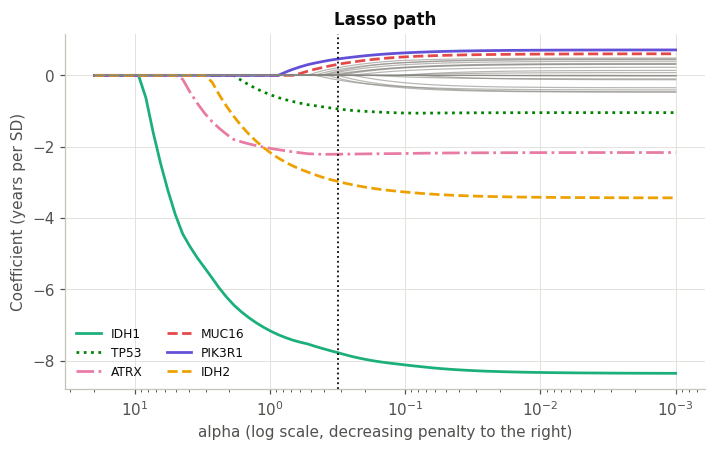

In [9]:
from sklearn.linear_model import LinearRegression, lasso_path
prep = FINAL["Lasso"][0].named_steps["prep"]
names = readable_names(prep.get_feature_names_out())
coefs = pd.DataFrame({
    "OLS (standardised)": FINAL["Linear regression"][0].named_steps["model"].coef_,
    f"Ridge (alpha = {FINAL['Ridge'][1]['alpha']:.3g})": FINAL["Ridge"][0].named_steps["model"].coef_,
    f"Lasso (alpha = {FINAL['Lasso'][1]['alpha']:.3g})": FINAL["Lasso"][0].named_steps["model"].coef_,
}, index=names)
coefs = coefs.reindex(coefs.iloc[:, 0].abs().sort_values(ascending=False).index)
display(coefs)
n_zero = int((np.abs(coefs.iloc[:, 2]) < 1e-10).sum())
print(f"Lasso sets {n_zero} of {len(coefs)} coefficients exactly to 0:",
      list(coefs.index[np.abs(coefs.iloc[:, 2]) < 1e-10]))
results["penalised_coefficients"] = coefs.to_dict(orient="index")
results["lasso_n_zero"] = n_zero
reporting.save_table_tex(coefs.rename_axis("Predictor").reset_index(), "reg_penalised_coefficients", float_format="{:+.2f}")

Z = prep.transform(X)
alphas, path, _ = lasso_path(Z, y - y.mean(), alphas=np.logspace(-3, 1.3, 80))
fig, ax = plt.subplots(figsize=(7.5, 4.2))
top = list(np.argsort(-np.abs(path[:, -1]))[:6])
styles = ["-", "--", "-.", ":", "-", "--"]
for j in range(path.shape[0]):
    if j in top:
        i = top.index(j)
        ax.plot(alphas, path[j], color=plotting.CATEGORICAL[(i + 2) % 8], ls=styles[i], lw=1.8, label=names[j])
    else:
        ax.plot(alphas, path[j], color=NEUTRAL, lw=0.8, alpha=0.6)
ax.axvline(FINAL["Lasso"][1]["alpha"], color=plotting.INK, ls=":", lw=1.2)
ax.set_xscale("log"); ax.invert_xaxis()
ax.set_xlabel("alpha (log scale, decreasing penalty to the right)"); ax.set_ylabel("Coefficient (years per SD)")
ax.set_title("Lasso path"); ax.legend(fontsize=8, ncol=2)
plotting.save_figure(fig, "reg_lasso_path")
plt.show()

## 9. Decision tree

The tuned tree (depth and minimum leaf size chosen by the inner CV on all patients) is drawn below. Each node shows the splitting rule, the number of patients and the mean age (the prediction) of the patients that reach it. The tree is easy to read but, as a single tree, it is a weak and unstable model (course summary, Chapter 8); its place in the comparison table shows the price of that interpretability.

Final tree hyperparameters: {'max_depth': 3, 'min_samples_leaf': 5} | leaves: 8 | depth: 3


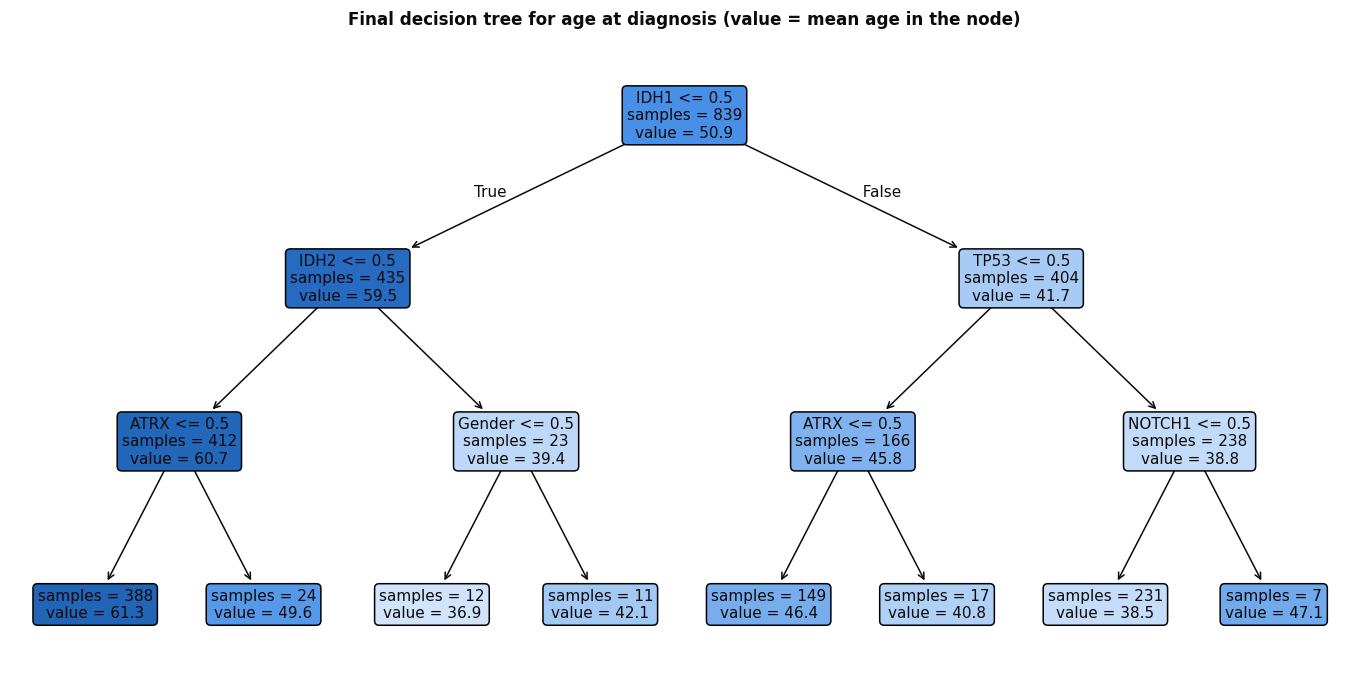

|--- IDH1 <= 0.5
|   |--- IDH2 <= 0.5
|   |   |--- ATRX <= 0.5
|   |   |   |--- value: [61.3]
|   |   |--- ATRX >  0.5
|   |   |   |--- value: [49.6]
|   |--- IDH2 >  0.5
|   |   |--- Gender <= 0.5
|   |   |   |--- value: [36.9]
|   |   |--- Gender >  0.5
|   |   |   |--- value: [42.1]
|--- IDH1 >  0.5
|   |--- TP53 <= 0.5
|   |   |--- ATRX <= 0.5
|   |   |   |--- value: [46.4]
|   |   |--- ATRX >  0.5
|   |   |   |--- value: [40.8]
|   |--- TP53 >  0.5
|   |   |--- NOTCH1 <= 0.5
|   |   |   |--- value: [38.5]
|   |   |--- NOTCH1 >  0.5
|   |   |   |--- value: [47.1]



In [10]:
from sklearn.tree import plot_tree, export_text
tree_pipe, tree_params = FINAL["Decision tree"]
tree = tree_pipe.named_steps["model"]
tree_names = readable_names(tree_pipe.named_steps["prep"].get_feature_names_out())
print("Final tree hyperparameters:", tree_params, "| leaves:", tree.get_n_leaves(), "| depth:", tree.get_depth())
fig, ax = plt.subplots(figsize=(min(3 + 1.6 * tree.get_n_leaves(), 20), 1.9 * tree.get_depth() + 2))
anns = plot_tree(tree, feature_names=tree_names, filled=True, rounded=True, impurity=False, precision=1, fontsize=10,
                 ax=ax, label="all")
plotting.recolor_tree(anns, tree, kind="regressor")   # project colours (darker = older)
ax.set_title("Final decision tree for age at diagnosis (value = mean age in the node)")
plotting.save_figure(fig, "reg_decision_tree")
plt.show()
print(export_text(tree, feature_names=tree_names, decimals=1))
results["tree"] = {"params": tree_params, "n_leaves": int(tree.get_n_leaves()), "depth": int(tree.get_depth())}

## 10. Permutation importance

How much does the RMSE get worse when one predictor is randomly shuffled? It is computed on each **outer test fold** with the model tuned on the corresponding training part, so it measures importance on unseen patients, and it is model-agnostic, so it can be compared between models. Race is shuffled as a single variable. Mean and SD over the 10 outer folds.

,Lasso,Random forest,XGBoost,SVR
IDH1,4.171e+00,3.016e+00,4.099,3.224
IDH2,5.851e-01,3.358e-01,0.512,0.479
ATRX,4.227e-01,6.261e-01,0.546,0.259
TP53,5.195e-02,2.122e-01,0.160,0.136
CIC,0.000e+00,1.810e-01,0.004,0.031
PTEN,-9.886e-03,9.859e-02,0.010,0.064
PIK3R1,7.992e-03,1.513e-02,0.008,0.034
FUBP1,-3.234e-03,2.152e-02,0.007,0.031
RB1,-8.262e-05,4.693e-04,0.013,0.041
Gender,-1.241e-03,3.971e-02,0.001,0.010


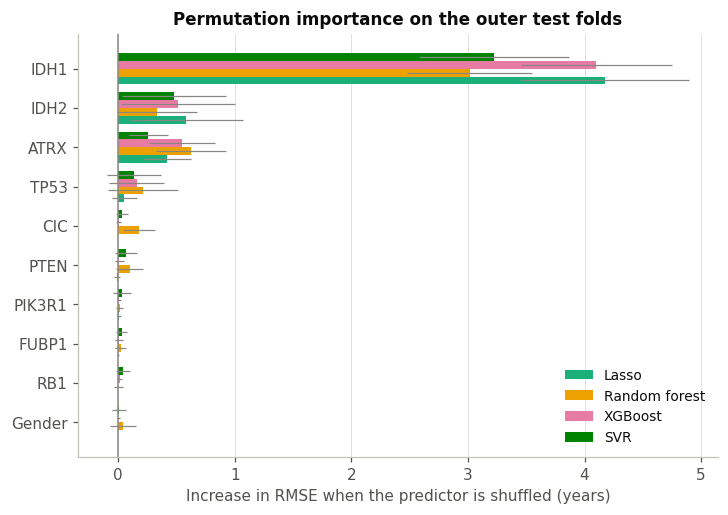

In [11]:
imp_models = ["Lasso", "Random forest", "XGBoost", "SVR"]
imp = pd.DataFrame({m: NESTED[m]["importance"].mean() for m in imp_models})
imp_sd = pd.DataFrame({m: NESTED[m]["importance"].std() for m in imp_models})
imp = imp.loc[imp.mean(axis=1).sort_values(ascending=False).index]
display(imp.head(10))
results["permutation_importance_mean"] = imp.to_dict(orient="index")
reporting.save_table_tex(imp.head(10).rename_axis("Predictor").reset_index(), "reg_permutation_importance", float_format="{:.2f}")

top10 = imp.index[:10][::-1]
fig, ax = plt.subplots(figsize=(7.5, 5))
h = 0.2
for i, m in enumerate(imp_models):
    ax.barh(np.arange(len(top10)) + (i - 1.5) * h, imp.loc[top10, m], xerr=imp_sd.loc[top10, m], height=h,
            color=plotting.CATEGORICAL[i + 2], label=m, error_kw=dict(ecolor=NEUTRAL, lw=0.8))
ax.set_yticks(np.arange(len(top10)), top10)
ax.axvline(0, color=NEUTRAL, lw=1)
ax.set_xlabel("Increase in RMSE when the predictor is shuffled (years)")
ax.set_title("Permutation importance on the outer test folds")
ax.legend(loc="lower right"); ax.grid(axis="y", visible=False)
plotting.save_figure(fig, "reg_permutation_importance")
plt.show()

## 11. Summary

Generated from the results above; saved in `results/logs/04_regression.json`.

In [12]:
s = summary.set_index("Model")
fmt = lambda m, k: f"{s.loc[m, k]:.2f} [{s.loc[m, k + ' CI low']:.2f}, {s.loc[m, k + ' CI high']:.2f}]"
fmt3 = lambda m, k: f"{s.loc[m, k]:.3f} [{s.loc[m, k + ' CI low']:.3f}, {s.loc[m, k + ' CI high']:.3f}]"
p_base = paired.set_index("Model")
summary_rows = [
    ("Mean baseline", f"MAE {fmt('Mean baseline', 'MAE')} years, R2 {fmt3('Mean baseline', 'R2')}"),
    ("Lowest MAE", f"{best_mae}: MAE {fmt(best_mae, 'MAE')} years, R2 {fmt3(best_mae, 'R2')}"),
    ("Models tied with it (overlapping MAE intervals)", ", ".join(ties_mae) if ties_mae else "none"),
    ("Improvement over the baseline", f"every model: MAE difference CI entirely below 0: "
                                      f"{bool((p_base['CI high (baseline)'] < 0).all())}"),
    ("Linear regression (in-sample, all data)", f"R2 = {ols.rsquared:.3f}; max VIF = {vif['VIF'].max():.2f}; "
                                                f"max Cook's distance = {np.nanmax(cooks):.3f} "
                                                f"({len(full_leverage)} patient with leverage 1 excluded)"),
    ("Strongest linear effects", ", ".join(f"{i} {r['Coefficient (years)']:+.1f} y" for i, r in coef.head(4).iterrows())),
    ("Lasso", f"alpha = {FINAL['Lasso'][1]['alpha']:.3g}; {n_zero} of {len(coefs)} coefficients set to 0"),
    ("Decision tree", f"depth {tree.get_depth()}, {tree.get_n_leaves()} leaves"),
    ("Most important predictor (permutation)", f"{imp.index[0]} (mean increase in RMSE {imp.iloc[0].mean():.2f} years)"),
    ("Link with the grade and IDH", f"correlation between predicted age ({best_mae}) and grade = {results['corr_prediction_grade']:.3f}, "
                                   f"and IDH status = {results['corr_prediction_idh']:.3f}"),
]
final_summary = pd.DataFrame(summary_rows, columns=["Topic", "Finding"])
with pd.option_context("display.max_colwidth", None):
    display(final_summary)
results["findings"] = dict(summary_rows)
reporting.save_table_tex(final_summary, "reg_summary", column_format="p{4.5cm}p{10.5cm}")
for name, r in NESTED.items():
    results.setdefault("folds", {})[name] = r["folds"].to_dict(orient="records")
path = reporting.save_json(results, "04_regression")
print("Saved", path.relative_to(config.ROOT))
print("Figures:", sorted(p.name for p in config.FIGURES.glob("reg_*.png")))

,Topic,Finding
0,Mean baseline,"MAE 13.23 [12.64, 13.80] years, R2 -0.002 [-0.008, -0.001]"
1,Lowest MAE,"Random forest: MAE 9.68 [9.15, 10.18] years, R2 0.397 [0.344, 0.446]"
2,Models tied with it (overlapping MAE intervals),"Linear regression, Ridge, Lasso, Decision tree, XGBoost, SVR"
3,Improvement over the baseline,every model: MAE difference CI entirely below 0: True
4,"Linear regression (in-sample, all data)",R2 = 0.414; max VIF = 2.61; max Cook's distance = 0.062 (1 patient with leverage 1 excluded)
5,Strongest linear effects,"IDH1 -16.7 y, IDH2 -21.0 y, ATRX -4.9 y, TP53 -2.1 y"
6,Lasso,alpha = 0.316; 11 of 25 coefficients set to 0
7,Decision tree,"depth 3, 8 leaves"
8,Most important predictor (permutation),IDH1 (mean increase in RMSE 3.63 years)
9,Link with the grade and IDH,"correlation between predicted age (Random forest) and grade = 0.705, and IDH status = -0.931"


Saved results\logs\04_regression.json
Figures: ['reg_decision_tree.png', 'reg_lasso_path.png', 'reg_model_comparison.png', 'reg_ols_diagnostics.png', 'reg_oof_predictions.png', 'reg_permutation_importance.png']
